# CNN — Cats vs Dogs

From-scratch ConvNet (no transfer learning). Aimed at **≥85% val accuracy** in about **10–15 min** on a Colab GPU.

**Public dataset:** [Hugging Face — `microsoft/cats_vs_dogs`](https://huggingface.co/datasets/microsoft/cats_vs_dogs) (Asirra / Kaggle cats vs dogs; 23,410 images). First download is ~700 MB.

**Kernel:** Python (ML .venv)

```powershell
cd Machine-Learning-Tasks
.\.venv\Scripts\Activate.ps1
pip install datasets
jupyter lab CNN\cnn_cats_dogs.ipynb
```


In [1]:
try:
    import google.colab  # type: ignore
    %pip install -q tensorflow datasets matplotlib
except ImportError:
    pass

In [2]:
from __future__ import annotations

import random

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from datasets import load_dataset
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

IMG_SIZE = (128, 128)
BATCH_SIZE = 64
L2 = keras.regularizers.l2(1e-4)
AUTOTUNE = tf.data.AUTOTUNE

# Faster matmul on T4 / Colab GPUs
keras.mixed_precision.set_global_policy("mixed_float16")

## Data pipeline

- **Train:** 80% of official `train` split.
- **Validation:** remaining 20%.
- Images are **decoded once** into NumPy arrays (avoids the slow HF generator every epoch).
- **Augmentation** on the training pipeline only.

In [3]:
print("Loading microsoft/cats_vs_dogs from Hugging Face...")
hf_full = load_dataset("microsoft/cats_vs_dogs", split="train")
hf_split = hf_full.train_test_split(
    test_size=0.2, seed=RANDOM_SEED, stratify_by_column="labels"
)
train_hf = hf_split["train"]
val_hf = hf_split["test"]
print(f"Train samples: {len(train_hf):,} | Val samples: {len(val_hf):,}")


def hf_to_arrays(hf_split):
    """Decode + resize once (uint8) so every epoch is fast and RAM stays ~1 GB."""
    images = np.empty((len(hf_split), *IMG_SIZE, 3), dtype=np.uint8)
    labels = np.empty((len(hf_split),), dtype=np.float32)
    for i, row in enumerate(hf_split):
        img = np.array(row["image"].convert("RGB"), dtype=np.uint8)
        img = tf.image.resize(img, IMG_SIZE)
        images[i] = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8).numpy()
        labels[i] = float(row["labels"])
        if (i + 1) % 5000 == 0:
            print(f"  decoded {i + 1:,}/{len(hf_split):,}")
    return images, labels


print("Decoding train images (one-time)...")
x_train, y_train = hf_to_arrays(train_hf)
print("Decoding val images (one-time)...")
x_val, y_val = hf_to_arrays(val_hf)
print(f"Arrays ready: train {x_train.shape} | val {x_val.shape}")


def make_tf_dataset(x, y, training: bool) -> tf.data.Dataset:
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    def preprocess(image: tf.Tensor, label: tf.Tensor) -> tuple[tf.Tensor, tf.Tensor]:
        image = tf.cast(image, tf.float32) / 255.0
        if training:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_brightness(image, max_delta=0.15)
            image = tf.image.random_contrast(image, 0.85, 1.15)
            image = tf.clip_by_value(image, 0.0, 1.0)
        return image, label

    if training:
        ds = ds.shuffle(len(x), seed=RANDOM_SEED, reshuffle_each_iteration=True)
    ds = ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_tf_dataset(x_train, y_train, training=True)
val_ds = make_tf_dataset(x_val, y_val, training=False)
print("TensorFlow datasets ready.")

Loading microsoft/cats_vs_dogs from Hugging Face...


README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

Train samples: 18,728 | Val samples: 4,682
Decoding train images (one-time)...
  decoded 5,000/18,728
  decoded 10,000/18,728
  decoded 15,000/18,728
Decoding val images (one-time)...
Arrays ready: train (18728, 128, 128, 3) | val (4682, 128, 128, 3)
TensorFlow datasets ready.


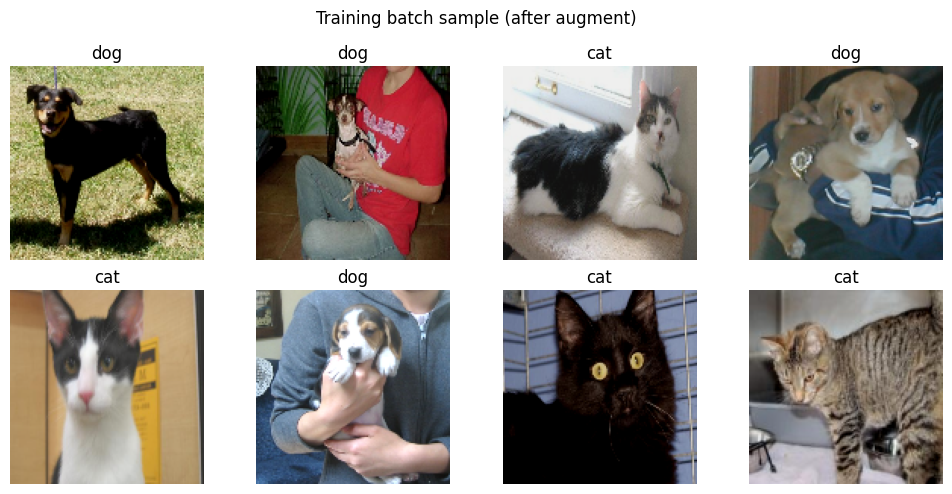

In [4]:
sample_batch = next(iter(train_ds.take(1)))
images, labels = sample_batch
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, img, lab in zip(axes.ravel(), images[:8], labels[:8]):
    ax.imshow(img.numpy())
    ax.set_title("dog" if lab.numpy() else "cat")
    ax.axis("off")
plt.suptitle("Training batch sample (after augment)")
plt.tight_layout()
plt.show()

## Model — from-scratch CNN

Three stages, **two** `Conv2D` layers each (64 → 128 → 256), BatchNorm, MaxPool, Dropout.  
Head: GlobalAveragePooling → Dense(256) → Dropout → sigmoid.

In [5]:
def conv_block(x: tf.Tensor, filters: int, dropout: float = 0.25) -> tf.Tensor:
    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return x


def build_cnn() -> keras.Model:
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = conv_block(inputs, 64, dropout=0.2)
    x = conv_block(x, 128, dropout=0.3)
    x = conv_block(x, 256, dropout=0.4)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=L2)(x)
    x = layers.Dropout(0.5)(x)
    # float32 output required under mixed_float16
    outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
    model = keras.Model(inputs, outputs, name="cats_dogs_cnn")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


model = build_cnn()
model.summary()

Model: "cats_dogs_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,215,041 (4.64 MB)

 Trainable params: 1,213,249 (4.63 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 84s 185ms/step - accuracy: 0.6031 - loss: 0.7449 - val_accuracy: 0.4998 - val_loss: 0.7924 - learning_rate: 0.0010
Epoch 2/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 30s 101ms/step - accuracy: 0.6562 - loss: 0.6750 - val_accuracy: 0.6651 - val_loss: 0.6749 - learning_rate: 0.0010
Epoch 3/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 29s 99ms/step - accuracy: 0.7132 - loss: 0.6158 - val_accuracy: 0.5886 - val_loss: 0.7590 - learning_rate: 0.0010
Epoch 4/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 28s 96ms/step - accuracy: 0.7424 - loss: 0.5784 - val_accuracy: 0.5784 - val_loss: 0.8505 - learning_rate: 0.0010
Epoch 5/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 29s 100ms/step - accuracy: 0.7708 - loss: 0.5306 - val_accuracy: 0.7040 - val_loss: 0.6202 - learning_rate: 5.0000e-04
Epoch 6/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 29s 98ms/step - accuracy: 0.7923 - loss: 0.4988 - val_accuracy: 0.5350 - val_loss: 1.5826 - learning_rate: 5.0000e-04
Epoch 7/15
293/293 ━━━━━━━━━━━━━━━━━━━━ 29s 98ms/step - accuracy:

In [7]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"]))
train_at_best = float(history.history["accuracy"][best_epoch])
val_at_best = float(history.history["val_accuracy"][best_epoch])
gap = train_at_best - val_at_best

print(f"Validation accuracy (restored weights): {val_acc * 100:.2f}%")
print(f"Epoch with best val loss:               {best_epoch + 1}")
print(f"Train accuracy at that epoch:           {train_at_best * 100:.2f}%")
print(f"Val accuracy at that epoch:             {val_at_best * 100:.2f}%")
print(f"Train–val gap:       {gap * 100:.2f} pp")

if gap > 0.10:
    print("Warning: gap > 10 pp — training may be overfitting; best weights were restored via early stopping.")
assert val_acc >= 0.85, f"Need validation accuracy ≥ 85% (got {val_acc:.2%})"

Validation accuracy (restored weights): 86.84%
Epoch with best val loss:               10
Train accuracy at that epoch:           86.10%
Val accuracy at that epoch:             86.84%
Train–val gap:       -0.74 pp


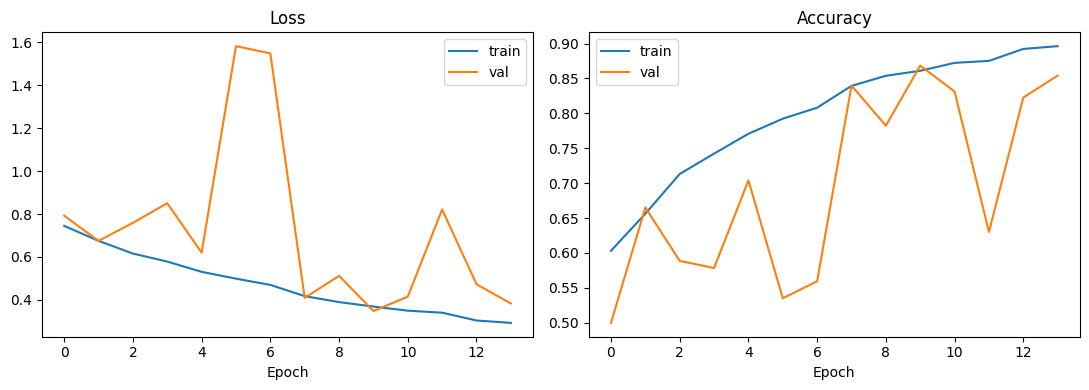

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()